<a href="https://colab.research.google.com/github/f2023-694-pixel/SmartCart-Analytics-data-mining/blob/main/SmartCart_Analytics_Midterm_Project_part_2_mining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

**Install Libraries**

In [ ]:
!pip install mlxtend

**Import Libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.cluster import KMeans

from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, silhouette_score
)

from mlxtend.frequent_patterns import fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder

sns.set_theme(style="whitegrid")

**Load Datasets**

In [ ]:
orders = pd.read_csv("/content/orders.csv")
order_products = pd.read_csv("/content/order_products__train.csv")
products = pd.read_csv("/content/products.csv")
aisles = pd.read_csv("/content/aisles.csv")
departments = pd.read_csv("/content/departments.csv")

print("Orders:", orders.shape)
print("Order Products:", order_products.shape)
print("Products:", products.shape)
print("Aisles:", aisles.shape)
print("Departments:", departments.shape)

Orders: (3421083, 7)
Order Products: (1384617, 4)
Products: (49688, 4)
Aisles: (134, 2)
Departments: (21, 2)


**Data Exploration**

In [ ]:
display(orders.head())
display(order_products.head())

print(orders.info())
print(orders.describe())

,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
1,2398795,1,prior,2,3,7,15.0
2,473747,1,prior,3,3,12,21.0
3,2254736,1,prior,4,4,7,29.0
4,431534,1,prior,5,4,15,28.0


,order_id,product_id,add_to_cart_order,reordered
0,1,49302,1,1
1,1,11109,2,1
2,1,10246,3,0
3,1,49683,4,0
4,1,43633,5,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3421083 entries, 0 to 3421082
Data columns (total 7 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   order_id                int64  
 1   user_id                 int64  
 2   eval_set                object 
 3   order_number            int64  
 4   order_dow               int64  
 5   order_hour_of_day       int64  
 6   days_since_prior_order  float64
dtypes: float64(1), int64(5), object(1)
memory usage: 182.7+ MB
None
           order_id       user_id  order_number     order_dow  \
count  3.421083e+06  3.421083e+06  3.421083e+06  3.421083e+06   
mean   1.710542e+06  1.029782e+05  1.715486e+01  2.776219e+00   
std    9.875817e+05  5.953372e+04  1.773316e+01  2.046829e+00   
min    1.000000e+00  1.000000e+00  1.000000e+00  0.000000e+00   
25%    8.552715e+05  5.139400e+04  5.000000e+00  1.000000e+00   
50%    1.710542e+06  1.026890e+05  1.100000e+01  3.000000e+00   
75%    2.565812e+06  1.543850e+

**Data Cleaning**

In [ ]:
orders = orders.drop_duplicates()
order_products = order_products.drop_duplicates()
products = products.drop_duplicates()

orders = orders.dropna(subset=["order_id", "user_id"])

order_products = order_products.dropna(
    subset=["order_id", "product_id", "reordered"]
)

print("Missing values:")
print(orders.isnull().sum())

Missing values:
order_id                       0
user_id                        0
eval_set                       0
order_number                   0
order_dow                      0
order_hour_of_day              0
days_since_prior_order    206209
dtype: int64


**Merge Datasets**

In [ ]:
train_orders = orders[orders["eval_set"] == "train"]

data = train_orders.merge(
    order_products, on="order_id"
)

data = data.merge(products, on="product_id")

data = data.merge(aisles, on="aisle_id", how="left")

data = data.merge(departments, on="department_id", how="left")

print("Final Dataset Shape:", data.shape)

display(data.head())

Final Dataset Shape: (1384617, 15)


,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_id,add_to_cart_order,reordered,product_name,aisle_id,department_id,aisle,department
0,1187899,1,train,11,4,8,14.0,196,1,1,Soda,77,7,soft drinks,beverages
1,1187899,1,train,11,4,8,14.0,25133,2,1,Organic String Cheese,21,16,packaged cheese,dairy eggs
2,1187899,1,train,11,4,8,14.0,38928,3,1,0% Greek Strained Yogurt,120,16,yogurt,dairy eggs
3,1187899,1,train,11,4,8,14.0,26405,4,1,XL Pick-A-Size Paper Towel Rolls,54,17,paper goods,household
4,1187899,1,train,11,4,8,14.0,39657,5,1,Milk Chocolate Almonds,45,19,candy chocolate,snacks


**Part A – Regression**
 Linear Regression**
Objective: Predict the number of days between customer orders.






In [ ]:
reg_data = orders[
    ["order_number", "order_dow",
     "order_hour_of_day", "days_since_prior_order"]
].dropna()

reg_data = reg_data.sample(
    min(200000, len(reg_data)),
    random_state=42
)

X = reg_data[
    ["order_number", "order_dow", "order_hour_of_day"]
]

y = reg_data["days_since_prior_order"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, predictions))
print("MSE:", mean_squared_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("R2 Score:", r2_score(y_test, predictions))

MAE: 6.957059853454749
MSE: 73.9094781512694
RMSE: 8.597062181423919
R2 Score: 0.12989676358918


**Regression Visualization**

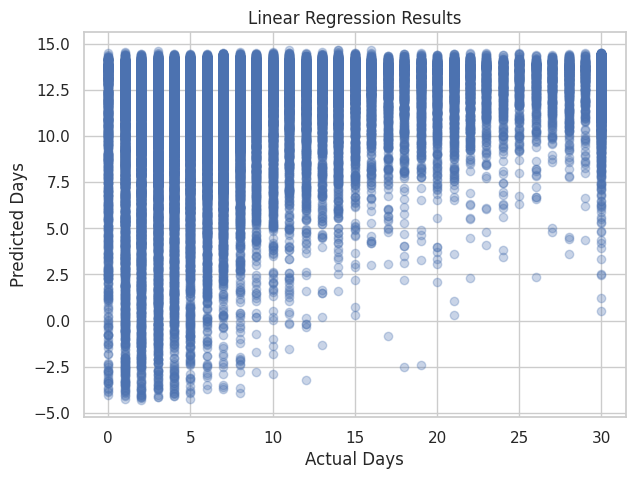

In [ ]:
plt.figure(figsize=(7,5))

plt.scatter(y_test, predictions, alpha=0.3)

plt.xlabel("Actual Days")
plt.ylabel("Predicted Days")

plt.title("Linear Regression Results")

plt.show()

**Part B – Classification**
Logistic Regression
Objective: Predict whether a customer will reorder a product.

In [ ]:
class_data = data[
    ["order_number", "order_dow",
     "order_hour_of_day", "add_to_cart_order",
     "department", "reordered"]
].dropna().copy()

class_data = class_data.sample(
    min(200000, len(class_data)),
    random_state=42
)

X = class_data.drop("reordered", axis=1)
y = class_data["reordered"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=42, stratify=y
)

numeric_cols = [
    "order_number", "order_dow",
    "order_hour_of_day", "add_to_cart_order"
]

categorical_cols = ["department"]

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_cols),

    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_cols)
])

classifier = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=500))
])

classifier.fit(X_train, y_train)

pred = classifier.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred))
print("Recall:", recall_score(y_test, pred))
print("F1 Score:", f1_score(y_test, pred))

Accuracy: 0.659525
Precision: 0.6698578663617056
Recall: 0.8536392405063291
F1 Score: 0.7506636641584739


**Confusion Matrix**

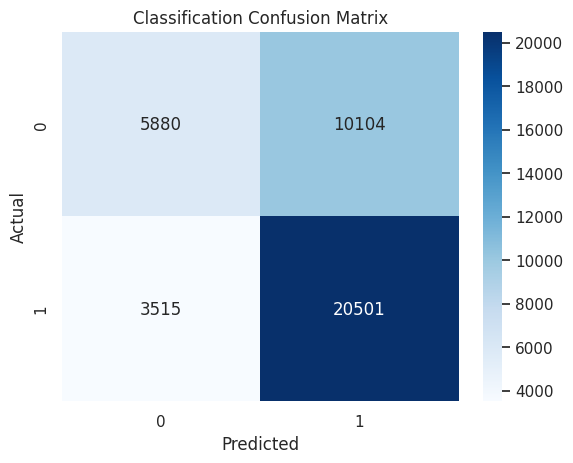

In [ ]:
cm = confusion_matrix(y_test, pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Classification Confusion Matrix")

plt.show()

**Part C – Association Rule Mining**
** Create shopping baskets**
Objective: Find products that customers frequently purchase together.

In [ ]:
basket_data = data[
    ["order_id", "product_name"]
].dropna().drop_duplicates()

unique_orders = basket_data["order_id"].unique()

sample_orders = np.random.default_rng(42).choice(
    unique_orders,
    size=min(30000, len(unique_orders)),
    replace=False
)

basket_data = basket_data[
    basket_data["order_id"].isin(sample_orders)
]

baskets = basket_data.groupby("order_id")[
    "product_name"
].apply(list)

print(baskets.head())

order_id
218     [Natural Artisan Water, Okra, Organic Yellow P...
719                             [Heavy Duty Scrub Sponge]
774     [Ice Cream Variety Pack, Nacho Cheese Sauce, D...
1001    [Tortilla Chips Organic Restaurant Style Purpl...
1275    [Boneless Skinless Chicken Breast, Organic Gar...
Name: product_name, dtype: object


**Convert into Transaction format**

In [ ]:
te = TransactionEncoder()

basket_array = te.fit(baskets).transform(baskets)

basket_df = pd.DataFrame(
    basket_array,
    columns=te.columns_
)

# Keep commonly purchased products to reduce memory
common_products = basket_df.sum().nlargest(300).index

basket_df = basket_df[common_products]

display(basket_df.head())

,Banana,Bag of Organic Bananas,Organic Strawberries,Organic Baby Spinach,Large Lemon,Organic Avocado,Organic Hass Avocado,Strawberries,Limes,Organic Raspberries,...,European Cucumber,Natural Chicken & Sage Breakfast Sausage,Organic Red Cabbage,Classic Hummus,Chocolate Chip Cookies,Non Fat Raspberry Yogurt,Organic Green Leaf Lettuce,Original Pure Creamy Almond Milk,Total 2% All Natural Plain Greek Yogurt,100 Calorie Per Bag Popcorn
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


**FP Growth**

In [ ]:
frequent_items = fpgrowth(
    basket_df,
    min_support=0.003,
    use_colnames=True
)

frequent_items = frequent_items.sort_values(
    "support", ascending=False
)

display(frequent_items.head(15))

,support,itemsets
21,0.142400,(Banana)
8,0.117367,(Bag of Organic Bananas)
26,0.083500,(Organic Strawberries)
71,0.074467,(Organic Baby Spinach)
15,0.061833,(Large Lemon)
22,0.056800,(Organic Avocado)
59,0.054700,(Organic Hass Avocado)
47,0.049400,(Strawberries)
91,0.046400,(Limes)
40,0.041567,(Organic Raspberries)


**Association Rules**

In [ ]:
rules = association_rules(
    frequent_items,
    metric="confidence",
    min_threshold=0.1
)

rules = rules.sort_values(
    "lift", ascending=False
)

display(
    rules[
        ["antecedents", "consequents",
         "support", "confidence", "lift"]
    ].head(15)
)

,antecedents,consequents,support,confidence,lift
261,(Lime Sparkling Water),(Sparkling Water Grapefruit),0.003800,0.241525,9.738928
262,(Sparkling Water Grapefruit),(Lime Sparkling Water),0.003800,0.153226,9.738928
243,(Red Peppers),(Green Bell Pepper),0.003900,0.166904,8.415349
242,(Green Bell Pepper),(Red Peppers),0.003900,0.196639,8.415349
294,"(Limes, Organic Avocado)",(Large Lemon),0.003667,0.464135,7.506227
165,(Jalapeno Peppers),(Limes),0.004700,0.334123,7.200932
164,(Limes),(Jalapeno Peppers),0.004700,0.101293,7.200932
296,"(Organic Avocado, Large Lemon)",(Limes),0.003667,0.328358,7.076686
173,(Bunched Cilantro),(Limes),0.004600,0.308036,6.638701
75,(Organic Yellow Onion),(Organic Garlic),0.006767,0.204844,6.600760


**Part D – K-Means Clustering**

Objective: Divide customers into three groups based on shopping behaviour.

In [ ]:
customer_data = orders.groupby("user_id").agg(
    total_orders=("order_id", "count"),

    avg_days=("days_since_prior_order", "mean"),

    avg_hour=("order_hour_of_day", "mean")
).reset_index()

customer_data = customer_data.fillna(0)

display(customer_data.head())

,user_id,total_orders,avg_days,avg_hour
0,1,11,19.000000,10.090909
1,2,15,16.285714,10.600000
2,3,13,12.000000,16.307692
3,4,6,17.000000,12.500000
4,5,5,11.500000,15.000000


**Apply K-means**

In [ ]:
features = customer_data[
    ["total_orders", "avg_days", "avg_hour"]
]

scaler = StandardScaler()

scaled_data = scaler.fit_transform(features)

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

customer_data["Cluster"] = kmeans.fit_predict(
    scaled_data
)

print(customer_data["Cluster"].value_counts())

Cluster
0    85021
1    84228
2    36960
Name: count, dtype: int64


**Cluster Analysis**

In [ ]:
cluster_summary = customer_data.groupby(
    "Cluster"
).agg(
    Customers=("user_id", "count"),
    Average_Orders=("total_orders", "mean"),
    Average_Days=("avg_days", "mean"),
    Average_Hour=("avg_hour", "mean")
)

display(cluster_summary.round(2))

,Customers,Average_Orders,Average_Days,Average_Hour
Cluster,,,,
0,85021,10.68,16.62,11.97
1,84228,9.97,17.78,15.32
2,36960,45.26,7.44,13.36


**Cluster Visualization**

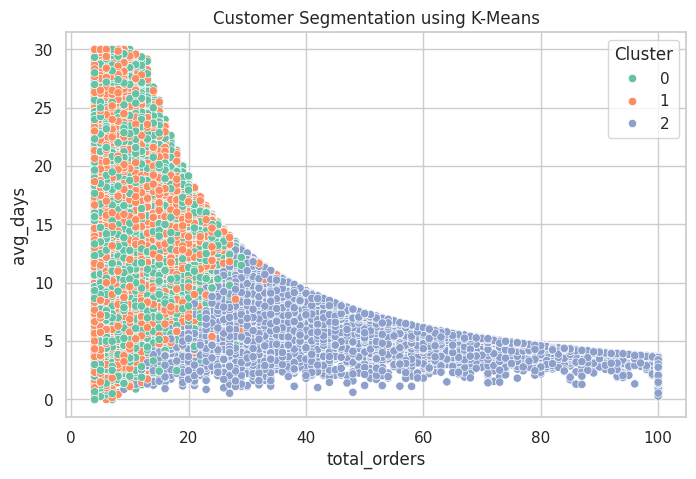

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=customer_data,
    x="total_orders",
    y="avg_days",
    hue="Cluster",
    palette="Set2"
)

plt.title("Customer Segmentation using K-Means")

plt.show()

**Evaluate Clustering**

In [ ]:
score = silhouette_score(
    scaled_data[:10000],
    customer_data["Cluster"].values[:10000]
)

print("Silhouette Score:", score)

Silhouette Score: 0.2940852547026839


**Part E – Final results**
**Compare algorithms**

In [ ]:
results = pd.DataFrame({
    "Technique": [
        "Regression",
        "Classification",
        "Association Mining",
        "Clustering"
    ],

    "Algorithm": [
        "Linear Regression",
        "Logistic Regression",
        "FP-Growth",
        "K-Means"
    ],

    "Purpose": [
        "Predict days between orders",
        "Predict product reorder",
        "Find products purchased together",
        "Group similar customers"
    ]
})

display(results)

,Technique,Algorithm,Purpose
0,Regression,Linear Regression,Predict days between orders
1,Classification,Logistic Regression,Predict product reorder
2,Association Mining,FP-Growth,Find products purchased together
3,Clustering,K-Means,Group similar customers


**Save Results**

In [ ]:
customer_data.to_csv(
    "customer_clusters.csv", index=False
)

frequent_items.to_csv(
    "frequent_itemsets.csv", index=False
)

rules.to_csv(
    "association_rules.csv", index=False
)

print("All project results saved successfully!")

All project results saved successfully!
